In [21]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt


In [22]:
# -----------------------------
# Load dataset
# -----------------------------
file_path = "Z:/Machine_learning Dr. Vimina/Machine Learning 2026/BCA H 2026/ML Lab Programs/iris.csv"

data = pd.read_csv(file_path)

print("Original Dataset")
print(data.head())

Original Dataset
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [23]:
print(data.describe())

       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000


In [24]:
# -----------------------------
# Encode Categorical Labels
# -----------------------------
encoder = LabelEncoder()

data["species"] = encoder.fit_transform(data["species"])

print("\nEncoded Labels")
print(data.head())



Encoded Labels
   sepal_length  sepal_width  petal_length  petal_width  species
0           5.1          3.5           1.4          0.2        0
1           4.9          3.0           1.4          0.2        0
2           4.7          3.2           1.3          0.2        0
3           4.6          3.1           1.5          0.2        0
4           5.0          3.6           1.4          0.2        0


In [25]:
# -----------------------------
# Separate Features and drop Target
# -----------------------------
X = data.drop(columns=["species"])



In [26]:
# -----------------------------
# Feature Scaling
# -----------------------------
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
print("\nScaled Features (First 5 rows)")
print(X_scaled[:5])



Scaled Features (First 5 rows)
[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


In [27]:
#Create the K-Means model
kmeans = KMeans(n_clusters=3,random_state=42,n_init=10)

# Perform clustering
y_kmeans = kmeans.fit_predict(X_scaled)



In [28]:
#Display cluster assignments
print("\nCluster assignments:")
print(y_kmeans)


Cluster assignments:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [29]:
#Display cluster centroids
print("\nCluster centroids (standardized feature space):")
print(kmeans.cluster_centers_)


Cluster centroids (standardized feature space):
[[-0.05021989 -0.88029181  0.34753171  0.28206327]
 [-1.01457897  0.84230679 -1.30487835 -1.25512862]
 [ 1.13597027  0.09659843  0.996271    1.01717187]]


In [32]:
#Count samples in each cluster
print("\nNumber of samples in each cluster:")

for cluster in range(3):
    count = np.sum(y_kmeans == cluster)
    print(f"Cluster {cluster}: {count} samples")


Number of samples in each cluster:
Cluster 0: 53 samples
Cluster 1: 50 samples
Cluster 2: 47 samples


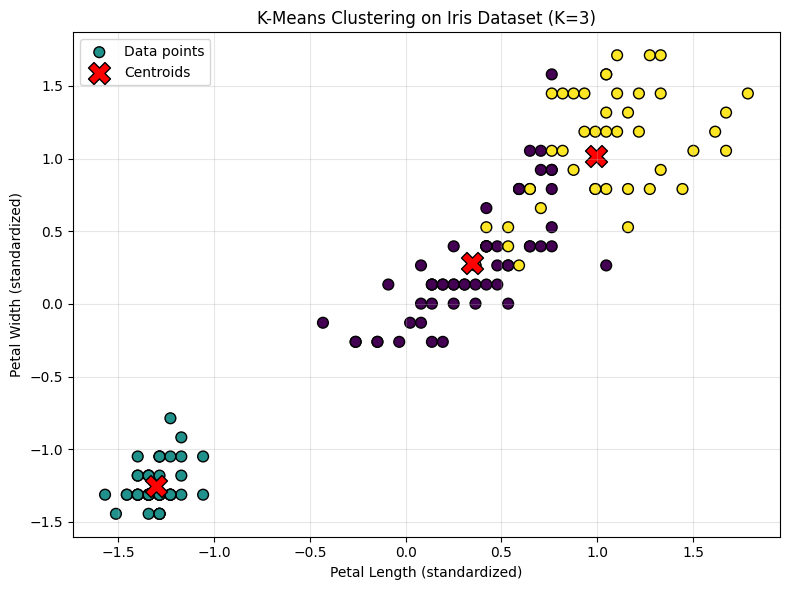

In [33]:
# 10. Visualize the clusters
# Use petal length and petal width for the plot

plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 2],
    X_scaled[:, 3],
    c=y_kmeans,
    cmap="viridis",
    s=60,
    edgecolor="black",
    label="Data points"
)

# Plot the centroids
centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 2],
    centroids[:, 3],
    marker="X",
    s=250,
    color="red",
    edgecolor="black",
    label="Centroids"
)

plt.xlabel("Petal Length (standardized)")
plt.ylabel("Petal Width (standardized)")
plt.title("K-Means Clustering on Iris Dataset (K=3)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [35]:
# Predict a new flower
sample = [[5.1, 3.5, 1.4, 0.2]]

# Scale the sample
sample_scaled = scaler.transform(sample)

# Predict the class
prediction = kmeans.predict(sample_scaled)

print("\nPredicted Species:", prediction)


Predicted Species: [1]


c:\Users\viminaer\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
